In [13]:
# Gerekli paketlerin yüklenmesi (Pkg.add("SDDP"); Pkg.add("HiGHS"))
using SDDP
using HiGHS
using Statistics
using Plots

In [6]:
function solve_alm_model()
    T = 12 # 12 aylık planlama ufku

    # SDDP Modeli: Linear Policy Graph oluşturulması
    model = SDDP.LinearPolicyGraph(
        stages = T,
        sense = :Max,
        upper_bound = 1_000_000.0, # <--- DÜZELTİLEN KISIM: lower_bound yerine upper_bound
        optimizer = HiGHS.Optimizer
    ) do sp, t
        # 1. DURUM DEĞİŞKENLERİ (State Variables)
        @variable(sp, 0 <= A <= 100_000, SDDP.State, initial_value = 1000.0)
        @variable(sp, 0 <= L <= 100_000, SDDP.State, initial_value = 800.0)

        # 2. KONTROL DEĞİŞKENLERİ
        @variable(sp, 0 <= new_asset <= 500.0)
        @variable(sp, 0 <= new_liability <= 500.0)
        @variable(sp, shortfall >= 0) # <--- YENİ: Regülasyon açığı (Slack variable)

        # 3. KISITLAR
        @constraint(sp, new_asset == new_liability)

        # Katı kısıt yerine esnek kısıt (Soft Constraint):
        # Eğer aktifler %110'u karşılayamazsa, model çökmez, aradaki fark "shortfall" değişkenine yazılır.
        @constraint(sp, A.out + shortfall >= 1.10 * L.out)

        # 4. RASSAL SÜREÇLER VE KATSAYI GÜNCELLEMESİ
        omegas = [
            (prob = 0.7, r_A = 0.025, r_L = 0.010),
            (prob = 0.3, r_A = 0.010, r_L = 0.035)
        ]
        
        # SDDP best-practice: Durum geçiş kısıtlarının şablonu dışarıda tanımlanır
        asset_eq = @constraint(sp, A.out == A.in + new_asset)
        liab_eq  = @constraint(sp, L.out == L.in + new_liability)

        SDDP.parameterize(sp, omegas) do ω
            # Çözücü "A.out - (1+r)*A.in - new_asset == 0" formatında çalıştığı için 
            # A.in ve L.in katsayılarını her senaryo için dinamik olarak değiştiriyoruz
            JuMP.set_normalized_coefficient(asset_eq, A.in, -(1 + ω.r_A))
            JuMP.set_normalized_coefficient(liab_eq, L.in, -(1 + ω.r_L))
        end

        # 5. AMAÇ FONKSİYONU
        # Regülasyon ihlaline çok yüksek bir ceza (penalty) uygulanır
        penalty = 10_000.0 * shortfall

        if t == T
            @stageobjective(sp, (A.out - L.out) - penalty)
        else
            # Ara dönemlerde sadece ihlal varsa cezası yansıtılır
            @stageobjective(sp, -penalty)
        end
    end

    # ==========================================
    # ÇÖZÜM VE EĞİTİM (Training)
    # ==========================================
    println("SDDP Algoritması Eğitiliyor...")
    # İleri ve geri yönlü geçişlerle (Forward/Backward passes) Bellman fonksiyonu yakınsaması
    SDDP.train(model, iteration_limit = 50, log_frequency = 10)

    # ==========================================
    # SİMÜLASYON VE TEST (Monte Carlo)
    # ==========================================
    println("Eğitilmiş model üzerinden Monte Carlo simülasyonları koşuluyor...")
    # Eğitilmiş optimal politika (policy) kullanılarak 100 farklı rassal rota simüle edilir
    simulations = SDDP.simulate(
        model, 
        100, 
        [:A, :L, :new_asset, :new_liability]
    )
    
    return model, simulations
end

solve_alm_model (generic function with 1 method)

In [7]:
# Modeli çalıştır
model, sims = solve_alm_model()

SDDP Algoritması Eğitiliyor...
-------------------------------------------------------------------
         SDDP.jl (c) Oscar Dowson and contributors, 2017-26
-------------------------------------------------------------------
problem
  nodes           : 12
  state variables : 2
  scenarios       : 4.09600e+03
  existing cuts   : false
options
  solver          : serial mode
  risk measure    : SDDP.Expectation()
  sampling scheme : SDDP.InSampleMonteCarlo
subproblem structure
  VariableRef                             : [8, 8]
  AffExpr in MOI.EqualTo{Float64}         : [3, 3]
  AffExpr in MOI.GreaterThan{Float64}     : [1, 1]
  VariableRef in MOI.GreaterThan{Float64} : [5, 6]
  VariableRef in MOI.LessThan{Float64}    : [5, 5]
numerical stability report
  matrix range     [1e+00, 1e+00]
  objective range  [1e+00, 1e+04]
  bounds range     [5e+02, 1e+06]
  rhs range        [0e+00, 0e+00]
-------------------------------------------------------------------
 iteration    simulation      bo

(A policy graph with 12 nodes.
 Node indices: 1, ..., 12
, Vector{Dict{Symbol, Any}}[[Dict(:bellman_term => -70315.20960103162, :noise_term => (prob = 0.7, r_A = 0.025, r_L = 0.01), :A => SDDP.State{Float64}(1000.0, 1025.0), :node_index => 1, :stage_objective => 0.0, :objective_state => nothing, :L => SDDP.State{Float64}(800.0, 808.0), :new_asset => -0.0, :new_liability => 0.0, :belief => Dict(1 => 1.0)…), Dict(:bellman_term => -19679.667717654258, :noise_term => (prob = 0.7, r_A = 0.025, r_L = 0.01), :A => SDDP.State{Float64}(1025.0, 1050.625), :node_index => 2, :stage_objective => 0.0, :objective_state => nothing, :L => SDDP.State{Float64}(808.0, 816.08), :new_asset => -0.0, :new_liability => 0.0, :belief => Dict(2 => 1.0)…), Dict(:bellman_term => -2377.588868997991, :noise_term => (prob = 0.7, r_A = 0.025, r_L = 0.01), :A => SDDP.State{Float64}(1050.625, 1076.890625), :node_index => 3, :stage_objective => 0.0, :objective_state => nothing, :L => SDDP.State{Float64}(816.08, 824.2408),

In [8]:
# İlk simülasyon rotasının son dönemindeki Özkaynak değerini yazdırma
final_stage_data = sims[1][end]
final_A = final_stage_data[:A].out
final_L = final_stage_data[:L].out
println("Simülasyon #1 Dönem Sonu Özkaynak: ", round(final_A - final_L, digits=2))

Simülasyon #1 Dönem Sonu Özkaynak: 187.13


In [10]:
# Tüm 100 simülasyonun dönem sonu (T=12) özkaynaklarını bir dizide toplayalım
final_equities = Float64[]

for sim in sims
    final_stage = sim[end] # 12. dönemin verisi
    A_out = final_stage[:A].out
    L_out = final_stage[:L].out
    push!(final_equities, A_out - L_out)
end

In [11]:
println("100 Simülasyonun Özeti:")
println("Ortalama Dönem Sonu Özkaynak : ", round(mean(final_equities), digits=2))
println("En Kötü Senaryo (Min)        : ", round(minimum(final_equities), digits=2))
println("En İyi Senaryo (Max)         : ", round(maximum(final_equities), digits=2))

100 Simülasyonun Özeti:
Ortalama Dönem Sonu Özkaynak : 186.61
En Kötü Senaryo (Min)        : 9.38
En İyi Senaryo (Max)         : 359.18


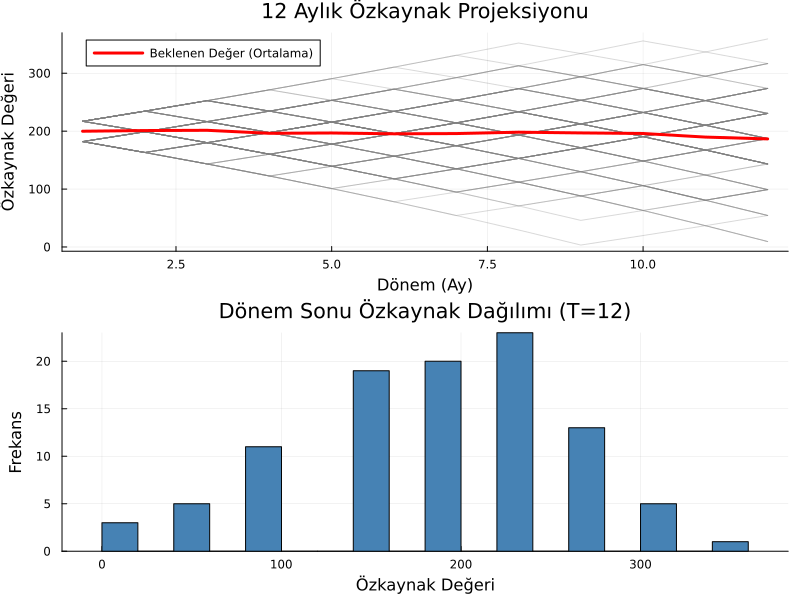

In [15]:
using Plots
using Statistics

T = 12 # Planlama ufku
num_sims = length(sims)

# Tüm simülasyonların 12 aylık özkaynak rotalarını tutacağımız matris
equity_paths = zeros(T, num_sims)

for (i, sim) in enumerate(sims)
    for t in 1:T
        A_t = sim[t][:A].out
        L_t = sim[t][:L].out
        equity_paths[t, i] = A_t - L_t
    end
end

# Her dönem için ortalama özkaynak rotası
mean_equity_path = mean(equity_paths, dims=2)

# 1. Grafik: Senaryo Rotaları (Spaghetti Plot)
# label = "" diyerek 100 rassal senaryonun lejantta yer kaplamasını engelliyoruz
p1 = plot(1:T, equity_paths, 
    label = "", 
    color = :gray, 
    alpha = 0.3, 
    title = "12 Aylık Özkaynak Projeksiyonu",
    xlabel = "Dönem (Ay)",
    ylabel = "Özkaynak Değeri",
    linewidth = 1,
    grid = true,
    legend = :topleft
)

# Ortalama rotayı kırmızı çizgi ve tek bir lejant etiketiyle ekliyoruz
plot!(p1, 1:T, mean_equity_path, 
    color = :red, 
    linewidth = 3, 
    label = "Beklenen Değer (Ortalama)"
)

# 2. Grafik: Dönem Sonu Özkaynak Dağılımı (Histogram)
final_equities = equity_paths[T, :]
p2 = histogram(final_equities, 
    bins = 20, 
    color = :steelblue, 
    title = "Dönem Sonu Özkaynak Dağılımı (T=12)",
    xlabel = "Özkaynak Değeri",
    ylabel = "Frekans",
    legend = false,
    grid = true
)

# İki grafiği alt alta birleştirerek göster
plot(p1, p2, layout = (2,1), size = (800, 600))